## Drive the Mount

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## GitHub Link

https://github.com/Shishir1145/Module-6.git

## Load the Liabraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

## Load the Datesets

In [ ]:
train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Module Project/M-6/train.csv")
test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Module Project/M-6/test.csv")

### Check the Basic Info

In [ ]:
print("Training shape:", train.shape,
      "\nTesting shape:", test.shape,
      "\nMissing values in training data:", '\n',
      train.isnull().sum())


Training shape: (136429, 14) 
Testing shape: (90954, 13) 
Missing values in training data: 
 id                         0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


## Separate Target and Features

In [ ]:
target = "Machine failure"

# Exclude identifiers and failure-mode indicators.
excluded_columns = [
    "id",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = train.drop(columns=excluded_columns)
y = train[target]

# Keep the same feature columns for test data.
X_test_final = test[X.columns]

# Identify categorical and numerical columns.
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumerical features:", numerical_columns)
print("Categorical features:", categorical_columns)


Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Categorical features: ['Type']


## Train Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", X_train.shape[0])
print("Validation rows:", X_test.shape[0])


Training rows: 109143
Validation rows: 27286


## Preprocessing

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

## Model Training

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced_subsample",
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

model.fit(X_train, y_train)

print("\nModel training completed!")


Model training completed!


## Predicting on Seen Data

In [ ]:
y_pred = model.predict(X_test)

# Probability of class 1: machine failure.
y_prob = model.predict_proba(X_test)[:, 1]

## Evaluation

In [ ]:
print("\n========== CLASSIFICATION RESULTS ==========")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("Average Precision (PR-AUC):",
      round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))


========== CLASSIFICATION RESULTS ==========
Accuracy: 0.9857
Precision: 0.5679
Recall: 0.3791
F1 Score: 0.4547
ROC-AUC: 0.9153
Average Precision (PR-AUC): 0.3992

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99     26856
     Failure       0.57      0.38      0.45       430

    accuracy                           0.99     27286
   macro avg       0.78      0.69      0.72     27286
weighted avg       0.98      0.99      0.98     27286



## Graphs

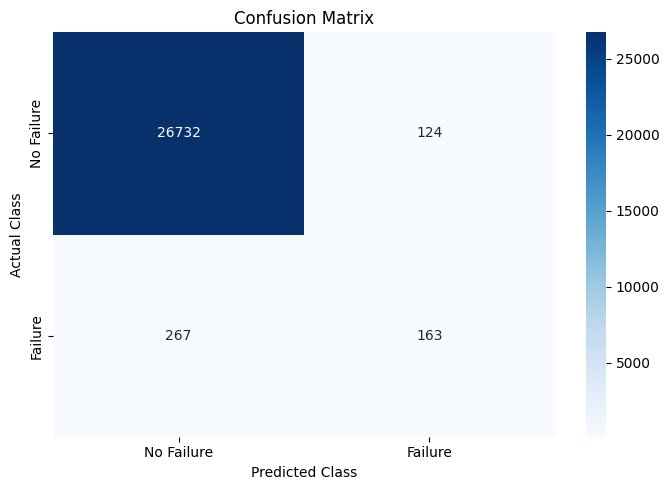

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

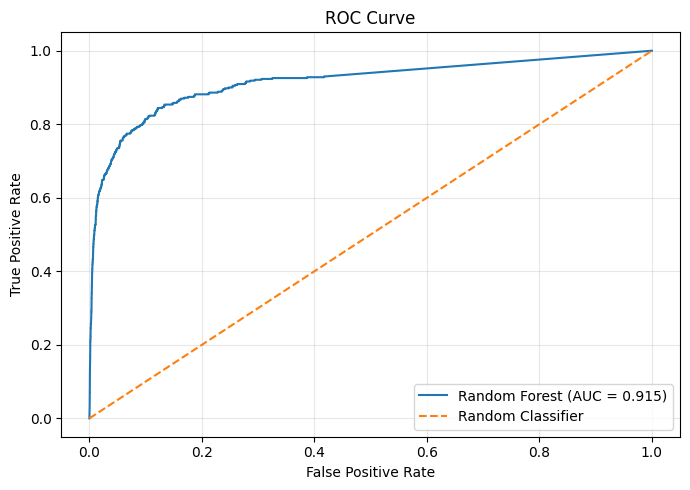

In [ ]:

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


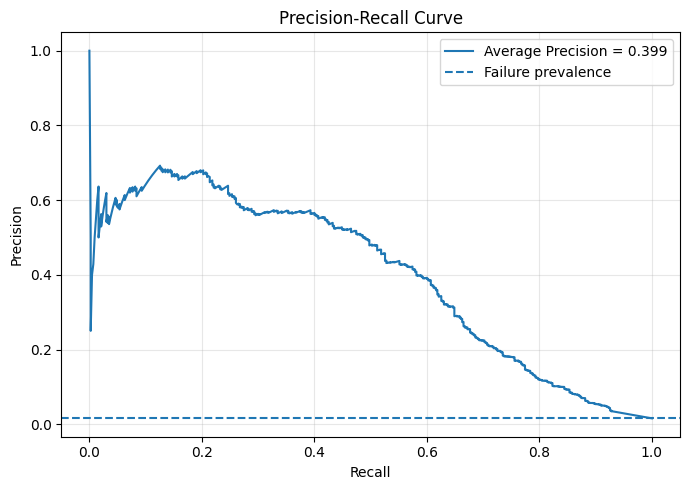

In [ ]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test, y_prob
)

ap = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"Average Precision = {ap:.3f}"
)

plt.axhline(
    y_test.mean(),
    linestyle="--",
    label="Failure prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final Training

In [ ]:
# After evaluating the model, retrain using all labeled data.
model.fit(X, y)

print("\nFinal model trained on all labeled training data.")


Final model trained on all labeled training data.


## Predicting on Unseen Data

In [ ]:
test_predictions = model.predict(X_test_final)

test_probabilities = model.predict_proba(
    X_test_final
)[:, 1]



## Saving the Result

In [ ]:
results = pd.DataFrame({
    "id": test["id"],
    "Machine failure": test_predictions,
    "Failure probability": test_probabilities
})

results.to_csv(
    "/content/drive/MyDrive/Colab Notebooks/Module Project/M-6/ Machine_failure_predictions.csv",
    index=False
)

print("\nTest predictions saved successfully!")
print(results.head())


Test predictions saved successfully!
       id  Machine failure  Failure probability
0  136429                0             0.000000
1  136430                0             0.212857
2  136431                0             0.000000
3  136432                0             0.004768
4  136433                0             0.000000
